Dimensões: (512, 512)
Tipo: uint8


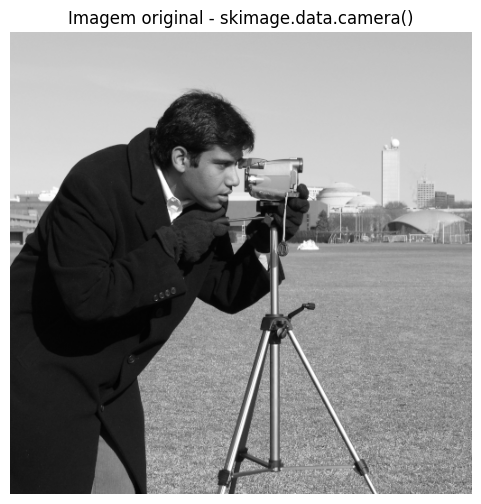

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Imagem de exemplo em escala de cinza
imagem_original = data.camera()

print("Dimensões:", imagem_original.shape)
print("Tipo:", imagem_original.dtype)

plt.figure(figsize=(6, 6))
plt.imshow(imagem_original, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem original - skimage.data.camera()")
plt.axis("off")
plt.show()

## 1. Convolução manual



In [2]:
def convolucao_manual(imagem, kernel):
    imagem = np.asarray(imagem, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if kernel.ndim != 2 or kernel.shape[0] % 2 == 0 or kernel.shape[1] % 2 == 0:
        raise ValueError("O kernel deve ser uma matriz 2D com dimensões ímpares.")

    altura, largura = imagem.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    imagem_pad = np.pad(
        imagem,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="reflect"
    )

    resultado = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):
            vizinhanca = imagem_pad[i:i + kh, j:j + kw]
            resultado[i, j] = np.sum(vizinhanca * kernel)

    return np.clip(resultado, 0, 255).astype(np.uint8)

## 2. Filtro de média



In [3]:
def filtro_media(imagem, tamanho=3):
    if tamanho <= 0 or tamanho % 2 == 0:
        raise ValueError("O tamanho deve ser um número ímpar positivo.")

    kernel = np.ones((tamanho, tamanho), dtype=np.float64)
    kernel /= kernel.sum()

    return convolucao_manual(imagem, kernel)


imagem_media = filtro_media(imagem_original, tamanho=3)

## 3. Filtros não lineares



In [4]:
def _percorrer_vizinhancas(imagem, tamanho, operacao):
    imagem = np.asarray(imagem)
    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (2D).")
    if tamanho <= 0 or tamanho % 2 == 0:
        raise ValueError("O tamanho deve ser um número ímpar positivo.")

    altura, largura = imagem.shape
    margem = tamanho // 2
    imagem_pad = np.pad(
        imagem,
        ((margem, margem), (margem, margem)),
        mode="reflect"
    )
    resultado = np.zeros((altura, largura), dtype=np.uint8)

    for i in range(altura):
        for j in range(largura):
            vizinhanca = imagem_pad[
                i:i + tamanho,
                j:j + tamanho
            ].ravel()
            resultado[i, j] = operacao(vizinhanca)

    return resultado


def filtro_mediana(imagem, tamanho=3):
    return _percorrer_vizinhancas(imagem, tamanho, np.median)


def filtro_moda(imagem, tamanho=3):
    def calcular_moda(vizinhanca):
        valores, frequencias = np.unique(vizinhanca, return_counts=True)
        # Em caso de empate, np.argmax seleciona o menor valor.
        return valores[np.argmax(frequencias)]

    return _percorrer_vizinhancas(imagem, tamanho, calcular_moda)


def filtro_maxima(imagem, tamanho=3):
    return _percorrer_vizinhancas(imagem, tamanho, np.max)


imagem_mediana = filtro_mediana(imagem_original, tamanho=3)
imagem_moda = filtro_moda(imagem_original, tamanho=3)
imagem_maxima = filtro_maxima(imagem_original, tamanho=3)

## 4. Comparação dos resultados


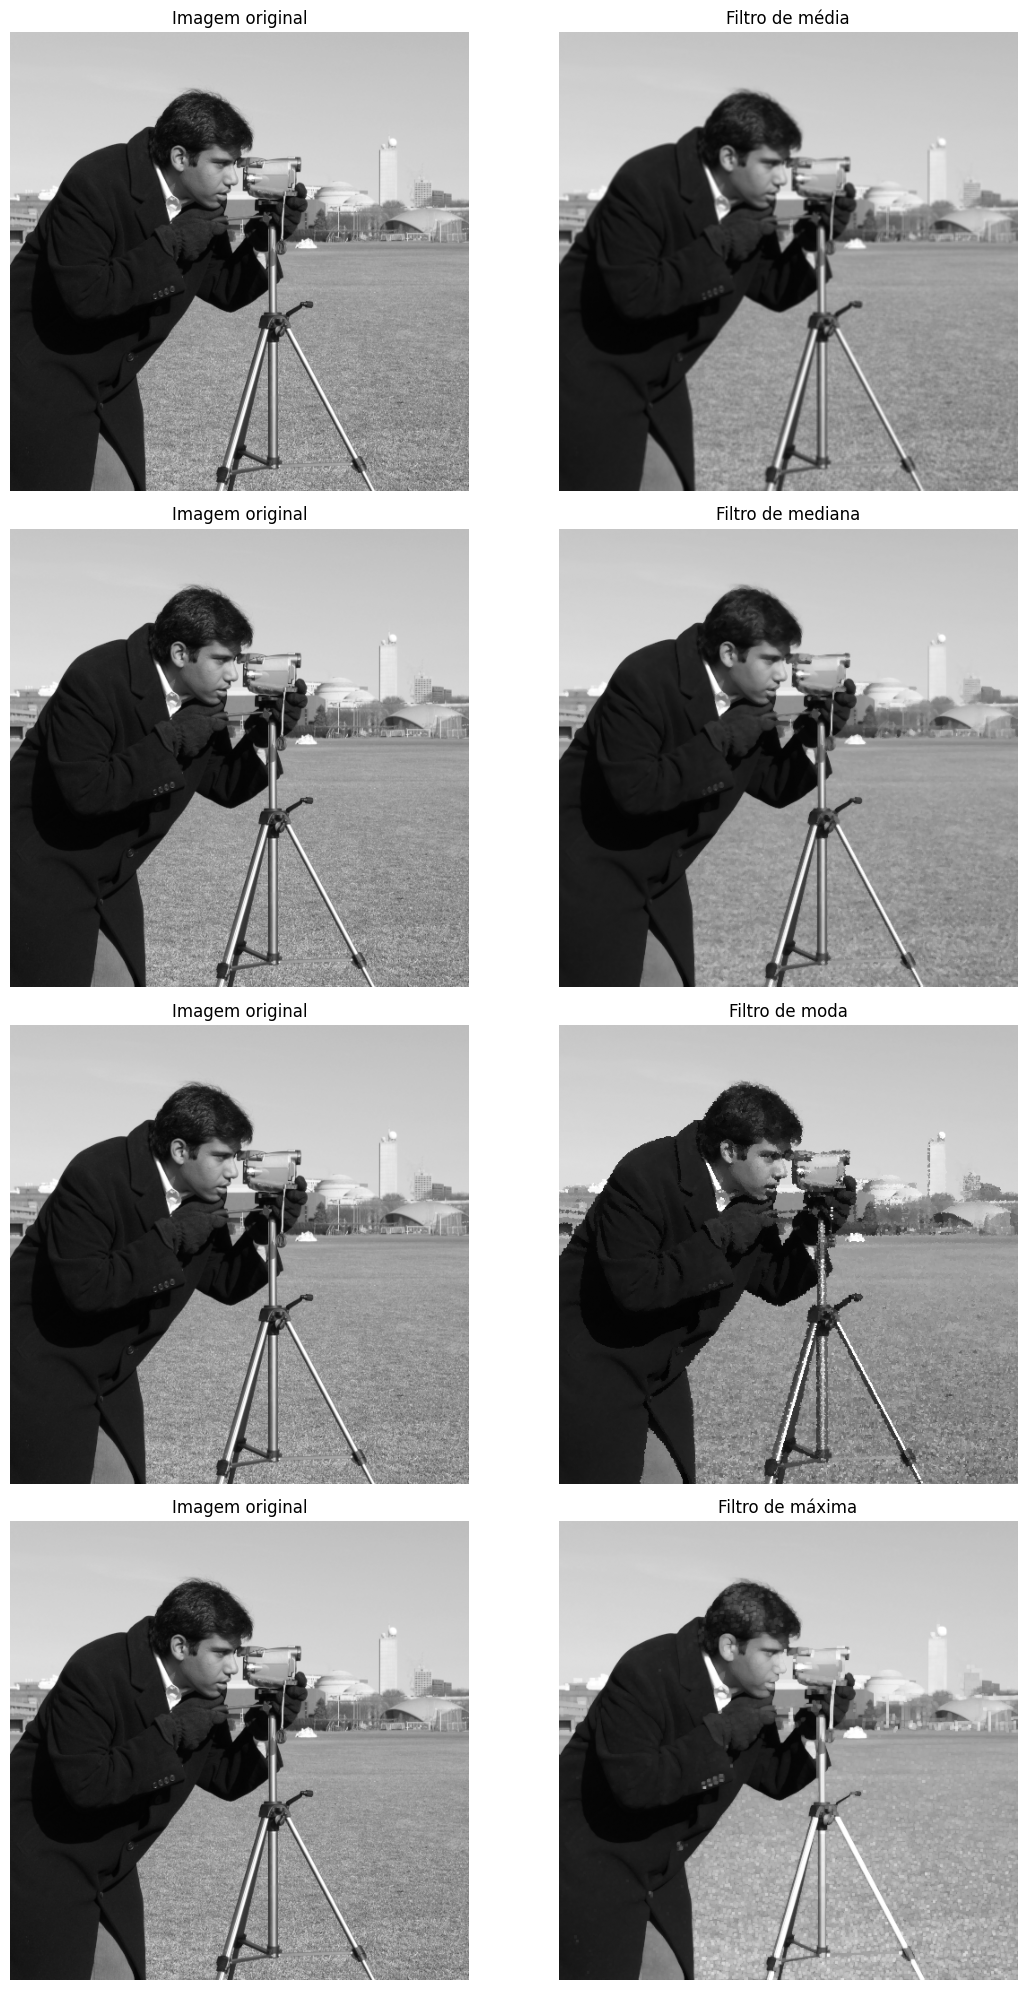

In [5]:
resultados = [
    ("Filtro de média", imagem_media),
    ("Filtro de mediana", imagem_mediana),
    ("Filtro de moda", imagem_moda),
    ("Filtro de máxima", imagem_maxima),
]

fig, eixos = plt.subplots(4, 2, figsize=(12, 20))

for linha, (nome, imagem_filtrada) in enumerate(resultados):
    eixos[linha, 0].imshow(imagem_original, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 0].set_title("Imagem original")
    eixos[linha, 0].axis("off")

    eixos[linha, 1].imshow(imagem_filtrada, cmap="gray", vmin=0, vmax=255)
    eixos[linha, 1].set_title(nome)
    eixos[linha, 1].axis("off")

plt.tight_layout()
plt.show()